# Phase 3 walkthrough — ML surrogates for DC-OPF LMPs

Reads the outputs of `python -m src.run --phases 3`. Sections: (1) the naive baseline and why it is exact without
congestion, (2) accuracy by bus and regime, (3) the main result — the Monte Carlo study rerun with the surrogate,
(4) the step-function failure analysis, (5) SHAP, (6) a live prediction with the trained models.

In [1]:
import os, sys, json, pickle
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
from IPython.display import Image, Markdown, display
from src.config import load_config, data_dir
cfg = load_config()
d = data_dir(cfg)
if not (d / "phase3" / "models.pkl").exists():
    from src.run import main; main(["--phases", "3"])
T = lambda name, **kw: pd.read_csv(f"reports/tables/{name}.csv", **kw)
summary = json.load(open("reports/phase3_summary.json"))

## 1. Baseline: the merit-order price
With no binding line, the DC-OPF LMP at every bus equals the copper-plate price: the offer of the cheapest unit
still needed after stacking all cheaper available capacity. It is computed analytically (no LP) and is exact on all
17,520 hourly cases. The surrogates receive it as a feature and learn only LMP − merit price (the congestion part).

In [2]:
from src.features import merit_order_price
from src.run import load_result
x = pd.read_parquet(d / "phase1" / "inputs.parquet")
copper = load_result(d / "phase1", "copper_")
p = merit_order_price(cfg, x)
print("max |merit-order price − copper-plate LP price| over 17,520 h:", float((p - copper.lmp['CAL']).abs().max()))

max |merit-order price − copper-plate LP price| over 17,520 h: 0.0


## 2. Accuracy on the 20,000 held-out MC scenarios

In [3]:
pd.DataFrame(summary["mc_task"]["summary_by_model"]).set_index("model").round(2)

,MAE,RMSE,MAE_congested,MAE_uncongested,P99_abs_error
model,,,,,
baseline (copper plate),3.50,13.86,10.42,0.07,23.67
LightGBM,0.84,11.02,2.08,0.22,11.18
MLP,1.19,9.67,2.73,0.42,13.33


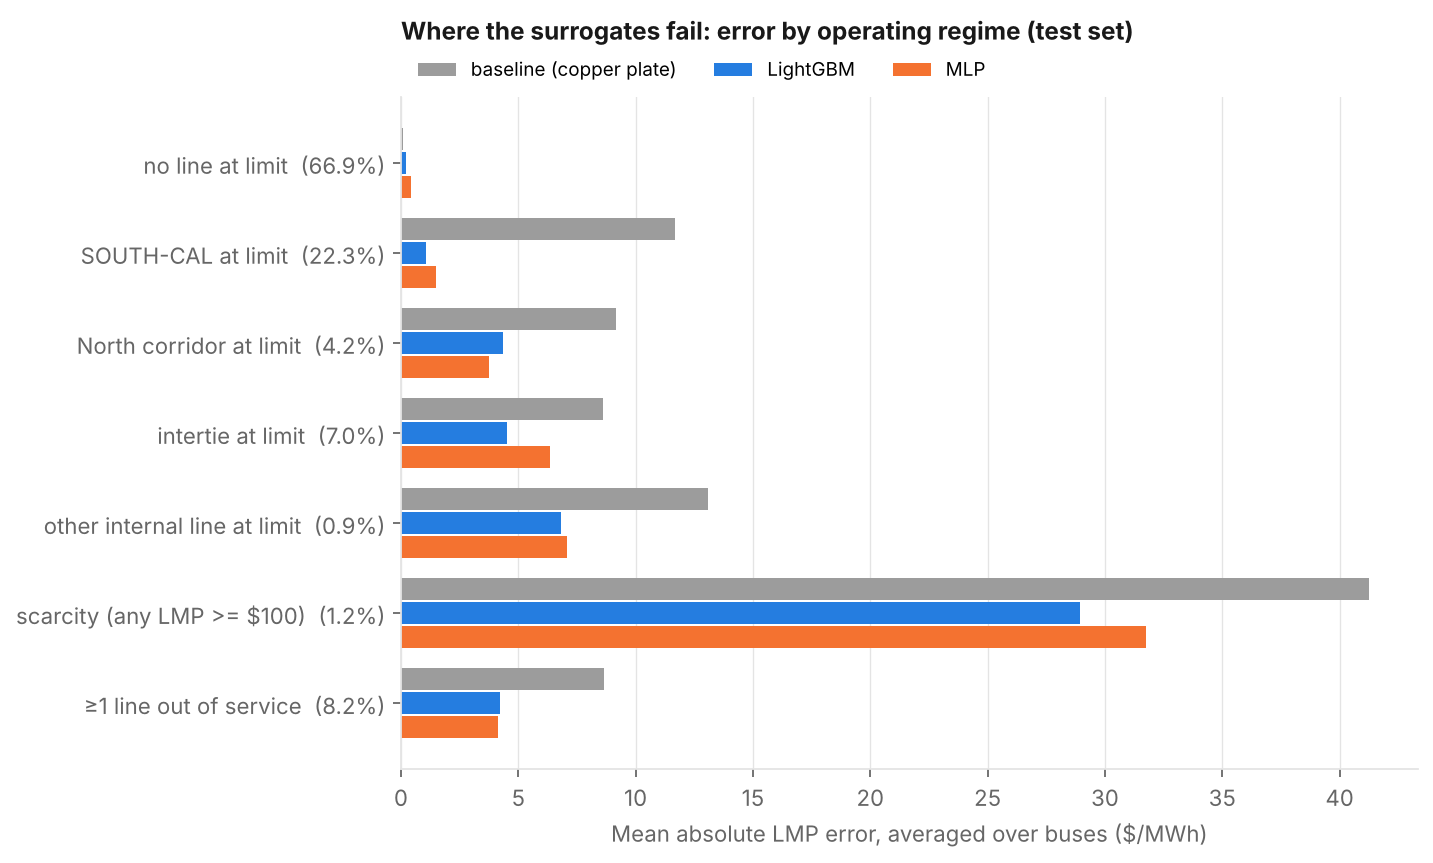

,share_of_rows,baseline (copper plate),LightGBM,MLP
no line at limit,0.67,0.07,0.22,0.42
SOUTH-CAL at limit,0.22,11.67,1.05,1.49
North corridor at limit,0.04,9.17,4.36,3.76
intertie at limit,0.07,8.63,4.51,6.35
other internal line at limit,0.01,13.08,6.82,7.09
scarcity (any LMP >= $100),0.01,41.27,28.92,31.76
≥1 line out of service,0.08,8.65,4.24,4.15


In [4]:
display(Image("reports/figures/surrogate_mae_by_regime.png", width=760))
T("surrogate_mc_regimes", index_col=0).round(2)

In [5]:
T("surrogate_ablation").set_index(["model", "target", "loss"]).round(2)

,,,MAE,RMSE,MAE_congested,MAE_uncongested,P99_abs_error,fit_seconds
model,target,loss,,,,,,
LightGBM,raw LMP,L2,1.61,16.09,3.45,0.70,21.52,8.86
MLP,raw LMP,L2,2.26,11.54,4.10,1.35,17.84,8.45
LightGBM,raw LMP,Huber,1.06,15.78,2.25,0.47,12.63,28.02
MLP,raw LMP,Huber,1.48,9.40,2.86,0.79,14.54,11.38
LightGBM,hybrid (LMP − merit price),L2,1.94,11.41,4.07,0.89,18.39,2.05
MLP,hybrid (LMP − merit price),L2,1.89,14.26,4.37,0.66,17.31,12.20
LightGBM,hybrid (LMP − merit price),Huber,0.84,11.02,2.08,0.22,11.18,8.21
MLP,hybrid (LMP − merit price),Huber,1.19,9.67,2.73,0.42,13.33,10.81


## 3. Main result: the Monte Carlo study with the surrogate

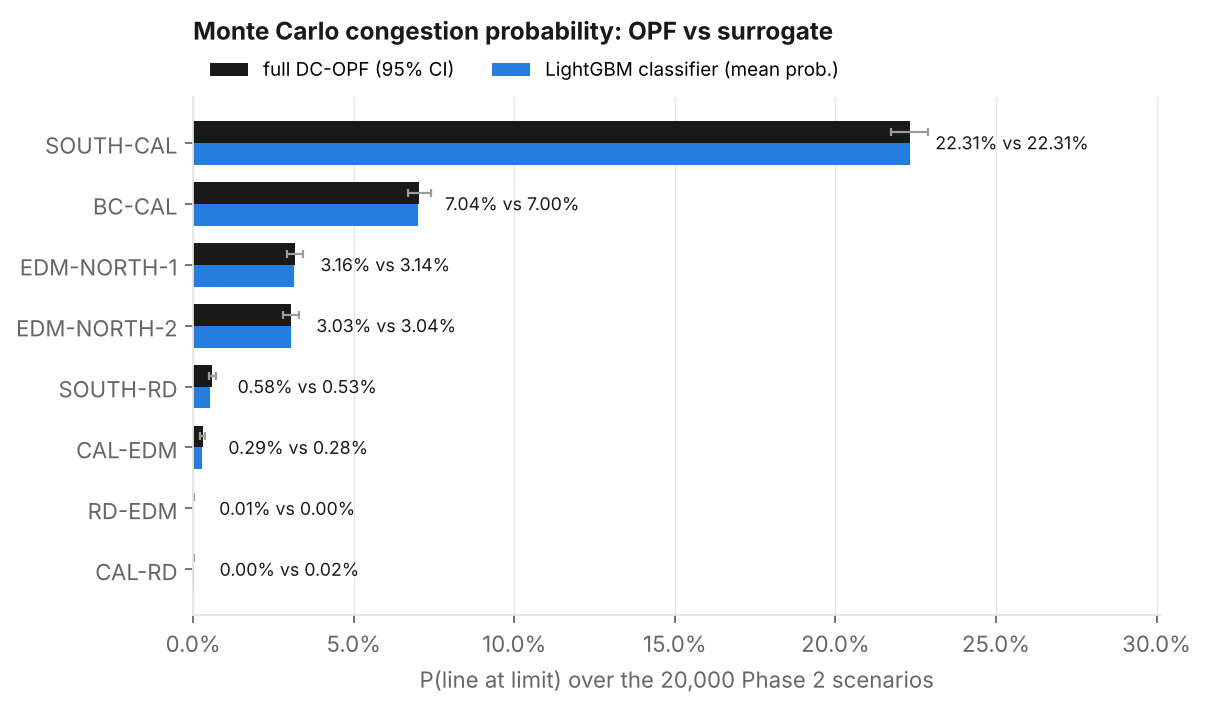

,opf_p,opf_ci95_low,opf_ci95_high,surrogate_p_mean_prob,surrogate_p_thresholded,abs_err_pp,within_opf_ci,opf_expected_h_per_year,surrogate_expected_h_per_year
SOUTH-CAL,0.2231,0.2174,0.2289,0.2231,0.2232,0.0024,True,1954.356,1954.1468
BC-CAL,0.0704,0.0669,0.0740,0.0700,0.0696,0.0445,True,616.704,612.8027
EDM-NORTH-1,0.0316,0.0293,0.0342,0.0314,0.0312,0.0267,True,277.254,274.9120
EDM-NORTH-2,0.0304,0.0281,0.0328,0.0304,0.0304,0.0029,True,265.866,266.1164
SOUTH-RD,0.0058,0.0049,0.0070,0.0053,0.0046,0.0574,True,51.246,46.2187
CAL-EDM,0.0030,0.0023,0.0038,0.0028,0.0026,0.0106,True,25.842,24.9139
RD-EDM,0.0001,0.0000,0.0004,0.0000,0.0000,0.0100,False,0.876,0.0000
CAL-RD,0.0000,0.0000,0.0002,0.0002,0.0000,0.0235,False,0.000,2.0612


In [6]:
display(Image("reports/figures/surrogate_mc_congestion.png", width=740))
T("surrogate_mc_congestion", index_col=0).round(4)

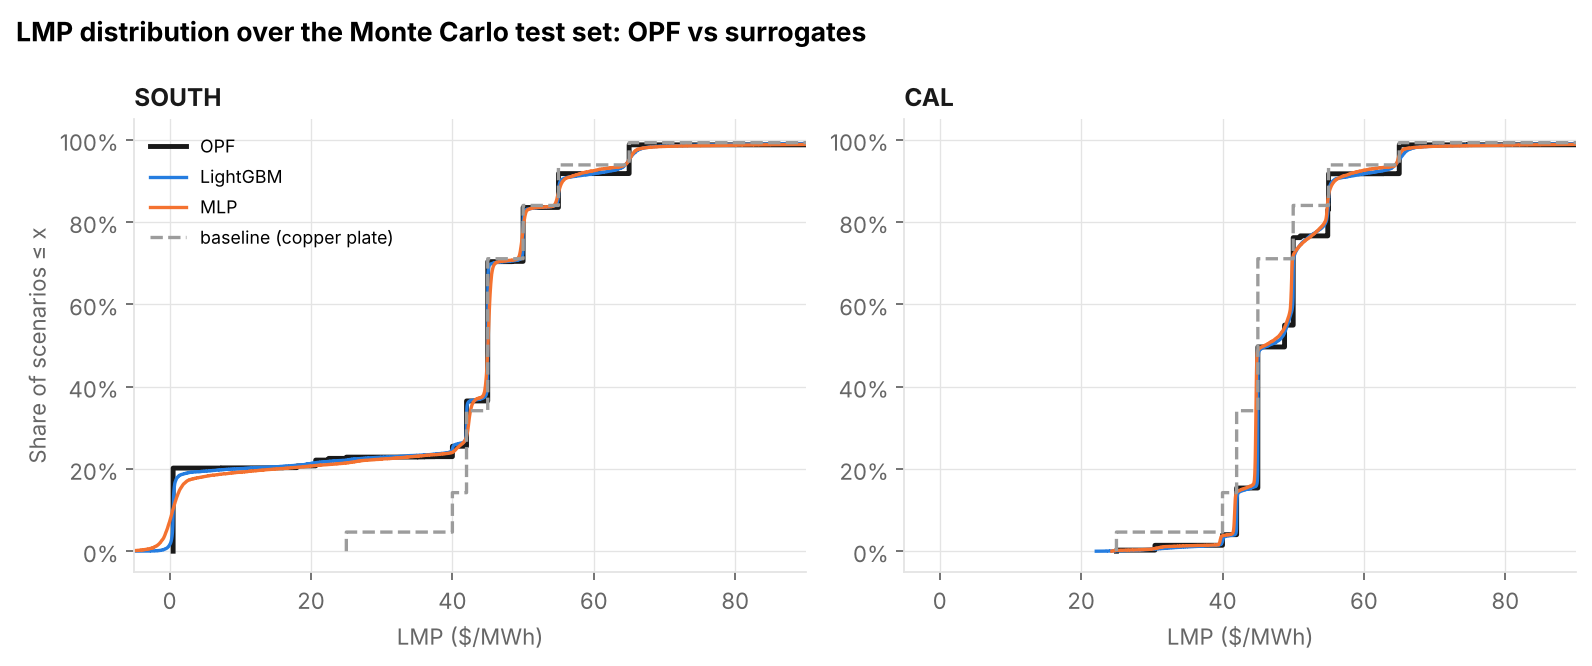

OPF  baseline (copper plate)  LightGBM    MLP
bus   stat                                                 
NORTH P10   40.00                    40.00     40.13  39.98
      P50   45.00                    45.00     45.00  44.88
      P90   55.00                    55.00     55.10  55.41
      mean  47.02                    46.46     46.98  46.98
EDM   P10   41.00                    40.00     40.62  40.44
      P50   45.00                    45.00     45.00  44.72
      P90   55.00                    55.00     55.21  55.22
      mean  47.85                    46.46     47.67  47.58
RD    P10   36.50                    40.00     36.67  37.15
      P50   45.00                    45.00     44.99  44.68
      P90   55.00                    55.00     55.27  55.23
      mean  46.97                    46.46     46.74  46.71
CAL   P10   42.00                    40.00     42.02  41.73
      P50   48.78                    45.00     46.52  45.98
      P90   55.00                    55.00     55.60  55.85
      mean  49.85                    46.46     49.62  49.59
SOUTH P10    0.50                    40.00      0.51   0.45
      P50   45.00                    45.00     45.00  45.02
      P90   55.00                    55.00     55.29  55.63
      mean  39.30                    46.46     38.87  39.41
BC    P10   42.00                    40.00     42.02  42.04
      P50   48.78                    45.00     46.55  46.12
      P90   55.00                    55.00     54.99  55.16
      mean  48.31                    46.46     48.31  48.23

In [7]:
display(Image("reports/figures/surrogate_lmp_ecdf.png", width=860))
T("surrogate_mc_quantiles").set_index(["bus", "stat"]).round(2)

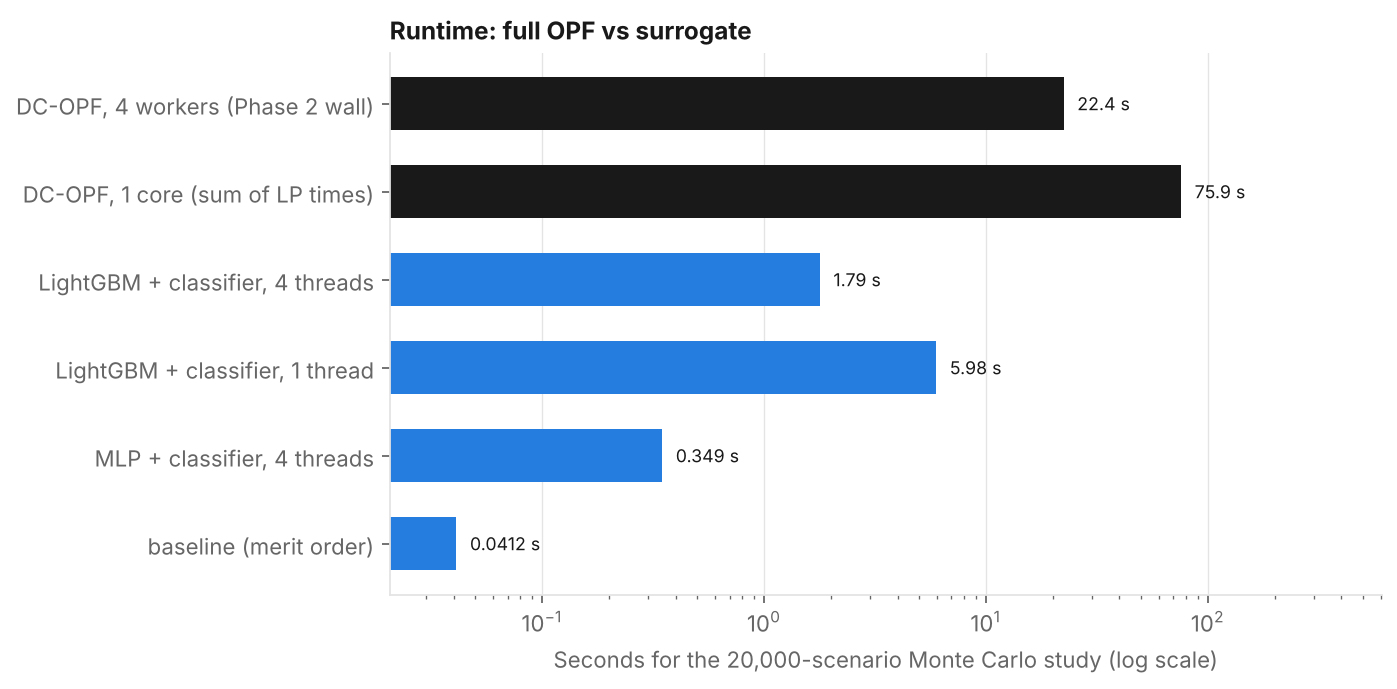

,seconds,speed-up vs OPF 4 workers,ms_per_scenario
"DC-OPF, 4 workers (Phase 2 wall)",22.4412,1.0000,1.1221
"DC-OPF, 1 core (sum of LP times)",75.8987,0.2957,3.7949
"LightGBM + classifier, 4 threads",1.7887,12.5459,0.0894
"LightGBM + classifier, 1 thread",5.9799,3.7528,0.2990
"MLP + classifier, 4 threads",0.3486,64.3776,0.0174
baseline (merit order),0.0412,544.5275,0.0021


break-even: 32,302 scenarios


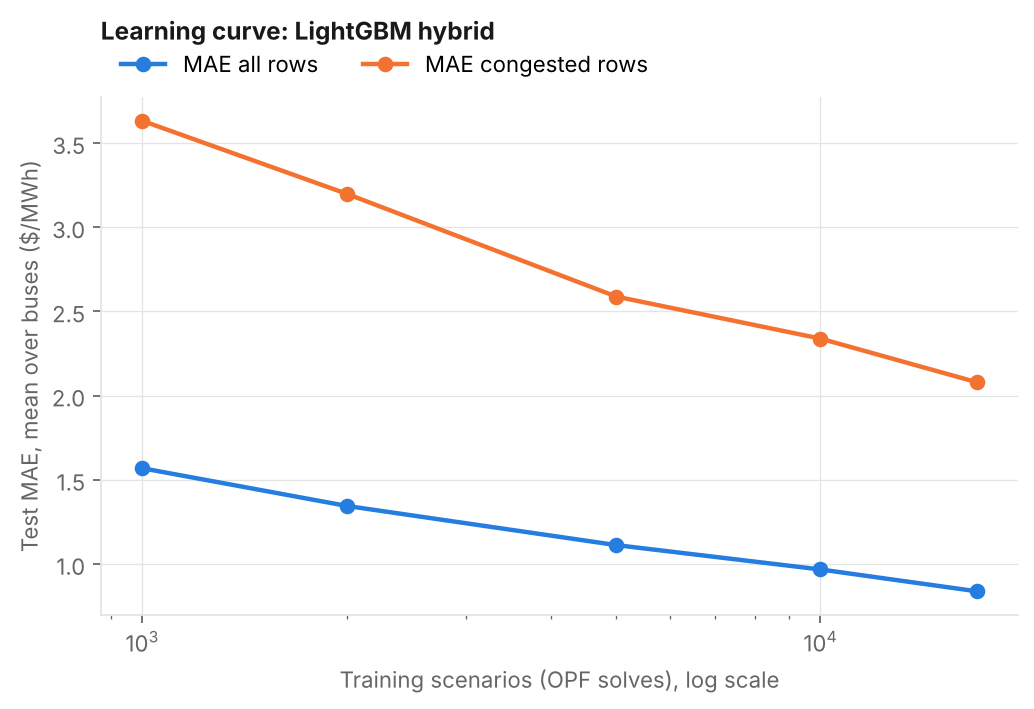

In [8]:
display(Image("reports/figures/surrogate_runtime.png", width=740))
display(T("surrogate_runtime", index_col=0).round(4))
print(f"break-even: {summary['mc_task']['break_even_scenarios']:,.0f} scenarios")
display(Image("reports/figures/surrogate_learning_curve.png", width=640))

## 4. LMP is a step function — where each model fails
One test hour, one input varied over 101 points, the OPF re-solved at each point.

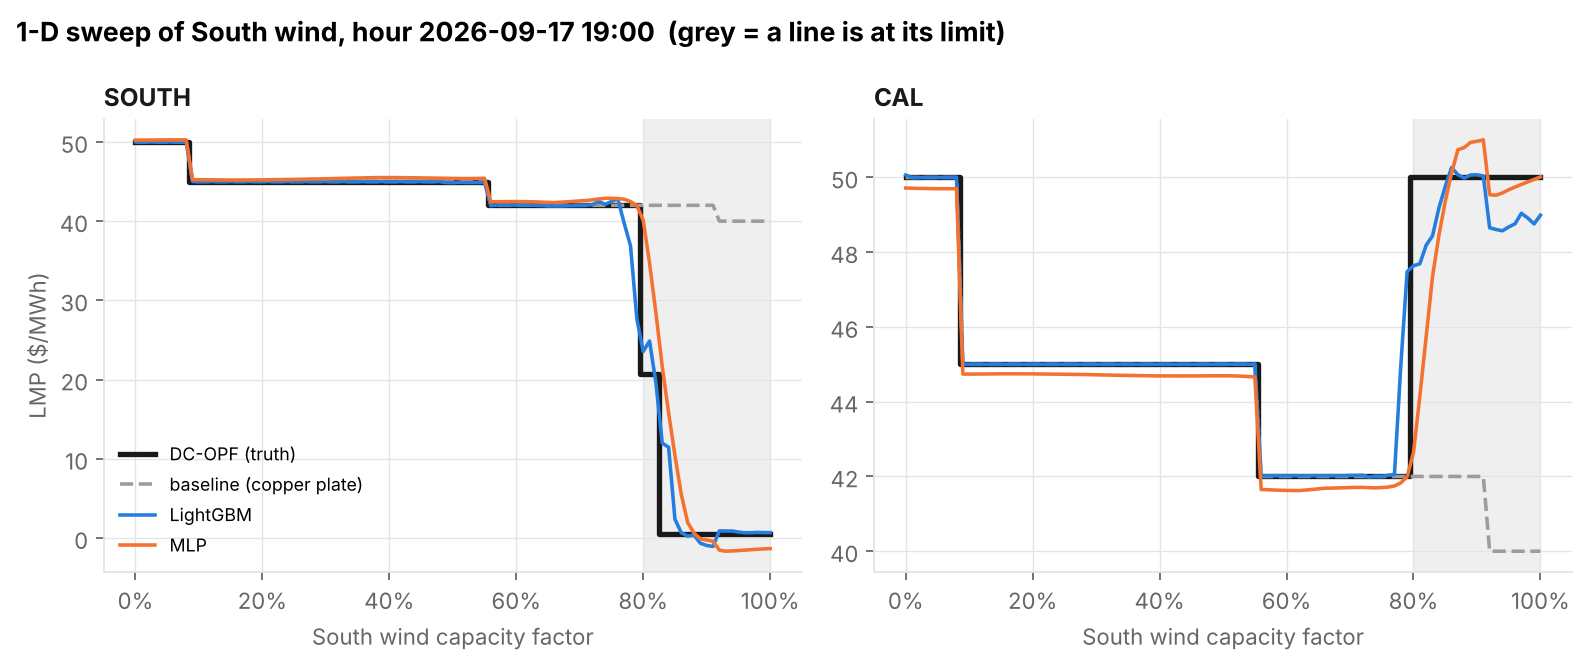

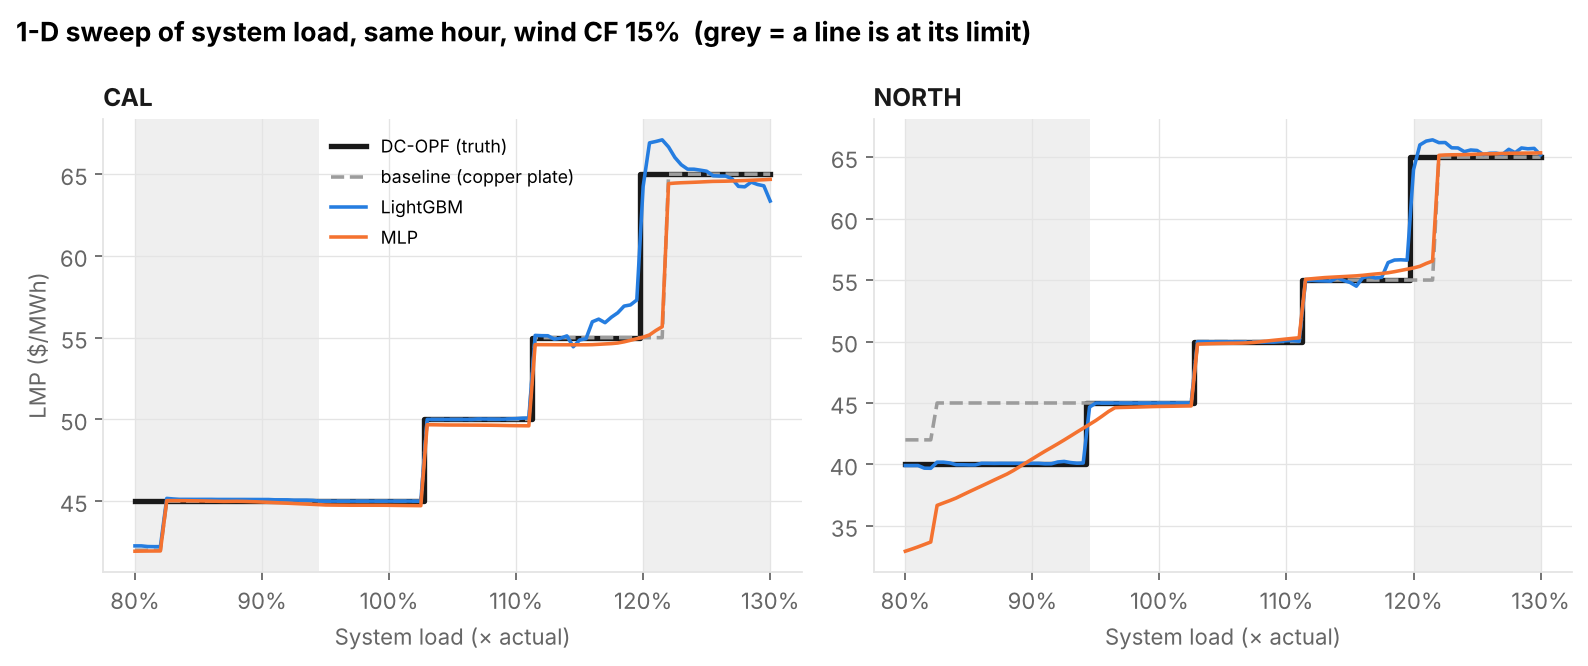

,baseline (copper plate),LightGBM,MLP
wind,4.85,0.47,0.98
load,1.11,0.37,1.05


In [9]:
display(Image("reports/figures/surrogate_step_wind.png", width=900))
display(Image("reports/figures/surrogate_step_load.png", width=900))
pd.DataFrame(summary["sweep_mae"]).T.round(2)

## 5. TreeSHAP

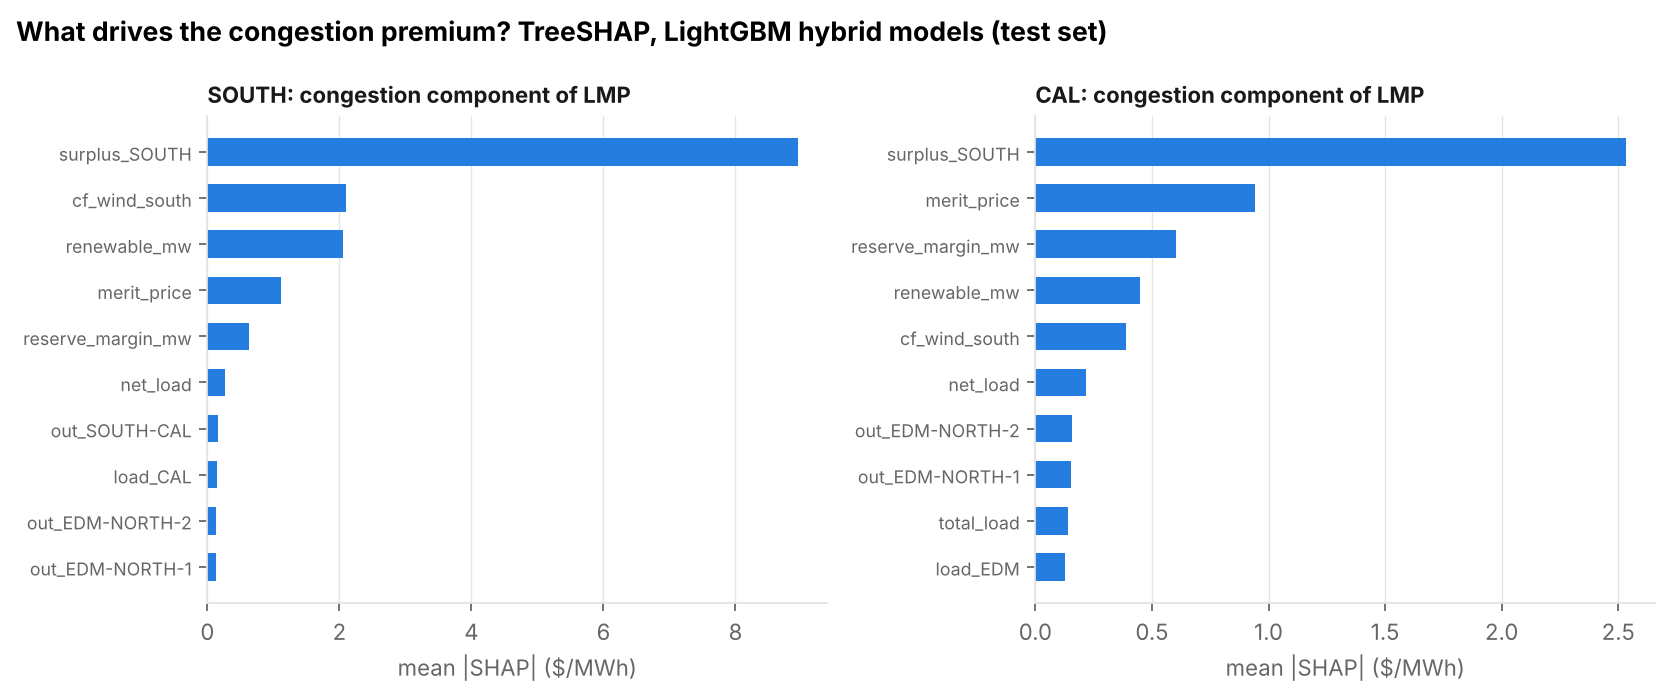

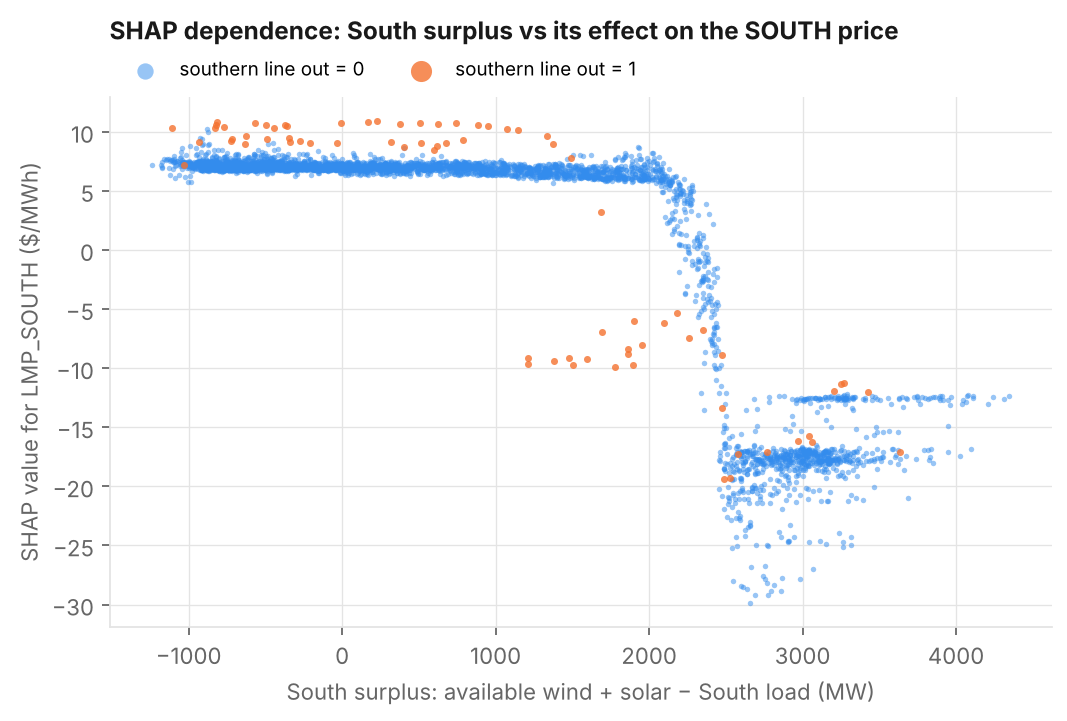

In [10]:
display(Image("reports/figures/surrogate_shap_importance.png", width=900))
display(Image("reports/figures/surrogate_shap_dependence.png", width=700))

## 6. Live prediction with the trained models
Take a test scenario, push South wind to 95 %, and compare the surrogates with a fresh OPF solve.

In [11]:
from src.montecarlo import Scenarios
from src.features import build_features
from src.simulate import solve_block
art = pickle.load(open(d / "phase3" / "models.pkl", "rb"))
scen = Scenarios(*(pd.read_parquet(d / "phase2" / f"mc_{k}.parquet") for k in ("inputs", "line_out", "gen_avail")))
i = scen.inputs.index[scen.line_out.sum(axis=1) == 0][7]
rows = scen.inputs.loc[[i, i]].copy(); rows.index = pd.RangeIndex(2, name="case")
rows.loc[1, "cf_wind_south"] = 0.95
ga = scen.gen_avail.loc[[i, i]].set_axis(rows.index)
lo = scen.line_out.loc[[i, i]].set_axis(rows.index)
X = build_features(cfg, rows, lo, ga)[art["feature_columns"]]
truth = solve_block(cfg, rows, gen_availability=ga).lmp.add_prefix("lmp_")
out = {"OPF": truth}
out.update({k: m.predict(X) for k, m in art["models"].items()})
res = pd.concat(out, names=["model", "case"]).round(2)
res.index = res.index.set_levels(["as sampled", "South wind 95%"], level="case")
display(res)
art["classifier"].predict_proba(X).round(3).set_axis(["as sampled", "South wind 95%"])

Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details


lmp_NORTH  lmp_EDM  lmp_RD  lmp_CAL  lmp_SOUTH  lmp_BC
model                   case                                                                  
OPF                     as sampled          45.00    45.00   45.00    45.00      45.00   45.00
                        South wind 95%      40.00    40.00   35.61    48.78       0.50   48.78
baseline (copper plate) as sampled          45.00    45.00   45.00    45.00      45.00   45.00
                        South wind 95%      25.00    25.00   25.00    25.00      25.00   25.00
LightGBM                as sampled          45.00    44.99   45.00    44.99      45.00   45.00
                        South wind 95%      40.22    40.26   35.85    48.96       0.11   49.10
MLP                     as sampled          45.10    44.74   44.82    44.93      44.60   45.01
                        South wind 95%      40.41    40.04   35.72    49.60      -0.52   48.08

,SOUTH-CAL,SOUTH-RD,CAL-RD,RD-EDM,CAL-EDM,EDM-NORTH-1,EDM-NORTH-2,BC-CAL
as sampled,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
South wind 95%,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
